## Library

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from scipy.stats import shapiro
from scipy.stats import kstest, norm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

sns.set_style("whitegrid")
sns.set_context("talk")
sns.set_palette(sns.color_palette("Reds_d", 5))

# IMPORT DATA

In [2]:
'''Import data : 
- Sumber = BigMart Sales Data.csv
- Nama = BigMart Sales
- Format = CSV
- Tujuan = Untuk menganalisa data tersebut
'''
data = pd.read_csv("BigMart Sales Data.csv")

# DATA EXPLORATION

### Data diubah menjadi Data Frame

In [3]:
bigmart = pd.DataFrame(data)
bigmart

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


##### Dataset memiliki dimensi :
##### Jumlah Baris = 8523
##### Jumlah Kolom = 12

In [4]:
bigmart.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 1.2 MB


##### info bertujuan untuk mengetahui tipe data pada setiap kolomnya.
##### bisa kita lihat pada kolom (Item_weight & Outlet_size) terdapat missing value
##### missing value yang nantinya akan ditangani pada tahap data cleaning
##### pada kolom Outlet_Establishment_Year juga nantinya akan diubah tipe data nya menjadi datetime, supaya menjadi format datetime bukan integer

In [5]:
bigmart.describe().round(2)

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.00,8523.00,8523.00,8523.00,8523.00
mean,12.86,0.07,140.99,1997.83,2181.29
std,4.64,0.05,62.28,8.37,1706.50
min,4.56,0.00,31.29,1985.00,33.29
25%,8.77,0.03,93.83,1987.00,834.25
50%,12.60,0.05,143.01,1999.00,1794.33
75%,16.85,0.09,185.64,2004.00,3101.30
max,21.35,0.33,266.89,2009.00,13086.96


Item_Weight, nilai mean dan median nya tidak terlalu berbeda maka simetris

Item_Visibility, nilai mean lebih besar dari median maka sedikit miring ke kanan karena nilainya tidak jauh berbeda

Item_MRP, nilai mean lebih kecil dari nilai mediannya maka sedikit miring kiri karena nilainya tidak jauh berbeda

Outlet_Establishment_Year,nilai standar deviasi nya 8.37 menunjukan bahwa tahun dalam dataset memiliki penyebaran sekitar 8 tahun dari nilai rata-ratanya yaitu 1997,83

Item_Outlet_Sales, nilai mean lebih besar daripada median maka miring kanan

In [6]:
bigmart.describe(include="string")

,Item_Identifier,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type
count,8523,8523,8523,8523,6113,8523,8523
unique,1559,5,16,10,3,3,4
top,FDG33,Low Fat,Fruits and Vegetables,OUT027,Medium,Tier 3,Supermarket Type1
freq,10,5089,1232,935,2793,3350,5577


Item_Identifier, memiliki ID untuk produk dan memperlihatkan 1559 unique, dengan ID FDG33 yang paling sering muncul (wajar karna 1 produk bisa dijual di outlet yang berbeda)

Item_Fat_Content, memiliki 5 kategori yang berbeda

Item_Type, memiliki 16 jenis produk, jenis produk yang sering muncul yaitu Fruits and Vegetables

Outlet_Identifier, menunjukan ada 10 ID outlet yang berbeda

Outlet_Size, memiliki 3 kategori outlet


Outlet_Location_Type, memiliki 3 kategori untuk lokasi outlet

Outlet_Type, memiliki 4 type outlet, dengan Supermarket Type1 yang paling sering muncul

In [7]:
bigmart.duplicated().sum()

np.int64(0)

In [8]:
duplicate_persentase = bigmart.duplicated().mean() * 100

print(f"Persentase duplicate: {duplicate_persentase:.2f}%")

Persentase duplicate: 0.00%


Tidak terdapat duplicate pada data tersebut

In [9]:
bigmart_clean = pd.DataFrame({
    "data_missing": bigmart.isna().sum(),
    "persentase": (bigmart.isna().mean()*100).round(2)
})

bigmart_clean = bigmart_clean[bigmart_clean["data_missing"]>0]
bigmart_clean

,data_missing,persentase
Item_Weight,1463,17.17
Outlet_Size,2410,28.28


Terdapat missing value pada kolom:

Item_Weight sebanyak 17%

Outlet_Size sebanyak 28%

In [10]:
bigmart["Outlet_Size"].value_counts()

#Total awal outlet size sebelum handling missing value

Outlet_Size
Medium    2793
Small     2388
High       932
Name: count, dtype: int64

#### Cek distribusi data

In [11]:
bigmart_distribusi = [["Item_Weight","Item_Visibility","Item_MRP","Item_Outlet_Sales"]]

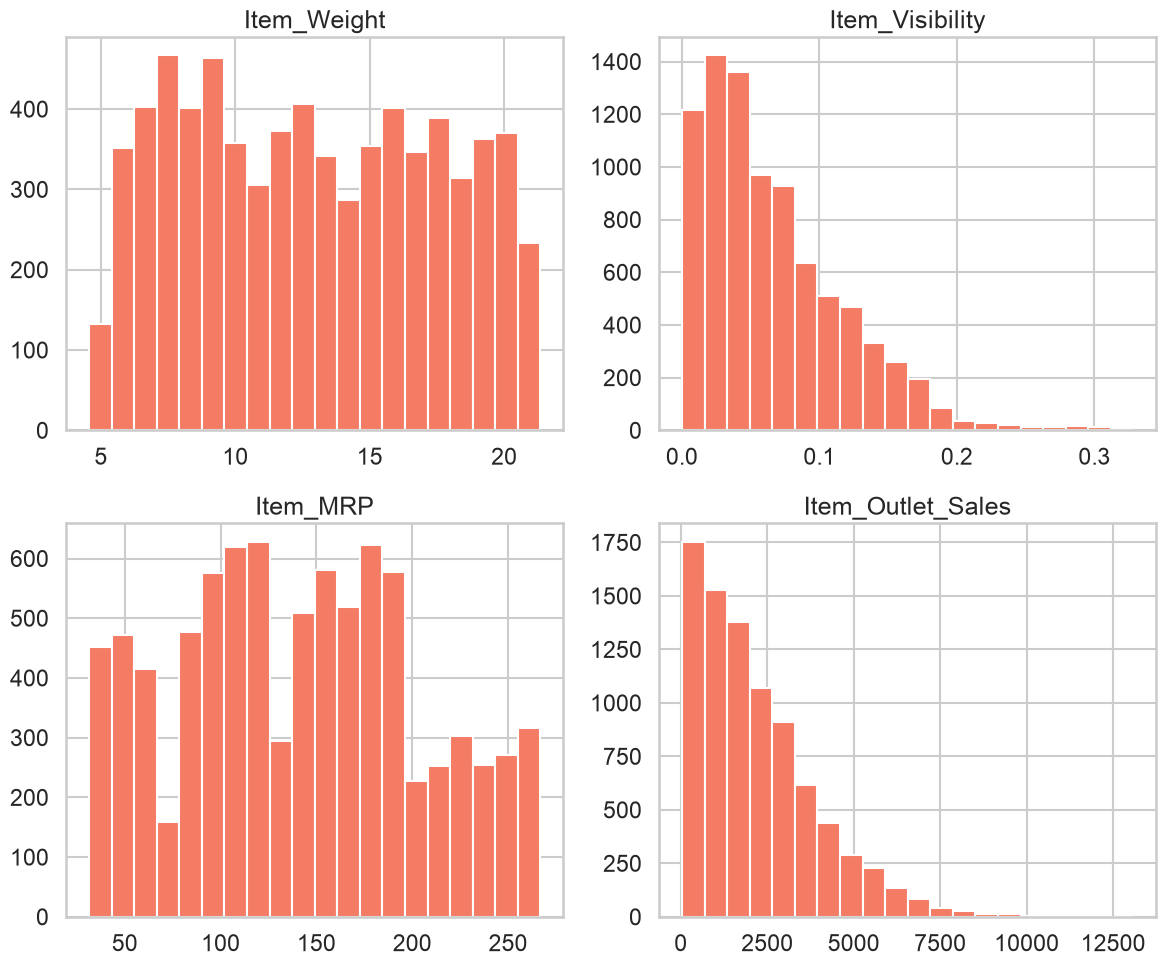

In [12]:
bigmart[bigmart_distribusi[0]].hist(
    bins=20,
    figsize=(12, 10)
)

plt.tight_layout()
plt.show()

Item_Weight terdistribusi uniform

Item_MRP terdistribusi non-simetris

Item_Visibility & Item_Outlet_Sales terdistribusi right-skewed atau miring kanan

INSIGHT AWAL

Insight dari data exploration yang bisa disimpulkan yaitu, dataset memiliki variabel numerik dan kategorikal, ditemukannya missing value pada kolom Item_Weight dan Outlet_Size yang perlu ditangani pada saat data cleaning, pada kolom Outlet_Establishment_Year juga perlu dibuah tipe datanya supaya menjadi format datetime agar lebih sesuai dan bukan integer. Pada kolom Item_Type menunjukan dominasi untuk jenis produk Fruits and Vegetables

# DATA PREPARATION

## DATA CLEANING

In [13]:
bigmart_copy = bigmart.copy()

### Inkonsistensi data

In [14]:
bigmart_copy["Item_Fat_Content"].unique()

<ArrowStringArray>
['Low Fat', 'Regular', 'low fat', 'LF', 'reg']
Length: 5, dtype: str

Terdapat inkonsistensi pada penulisan di kolom Item fat content

In [15]:
bigmart_copy["Item_Identifier"].unique()

<ArrowStringArray>
['FDA15', 'DRC01', 'FDN15', 'FDX07', 'NCD19', 'FDP36', 'FDO10', 'FDP10',
 'FDH17', 'FDU28',
 ...
 'FDB46', 'NCX17', 'FDH31', 'FDX13', 'NCU53', 'FDD28', 'FDU43', 'NCF55',
 'NCW30', 'NCW05']
Length: 1559, dtype: str

In [16]:
bigmart_copy["Item_Weight"].unique()

array([ 9.3  ,  5.92 , 17.5  , 19.2  ,  8.93 , 10.395, 13.65 ,    nan,
       16.2  , 11.8  , 18.5  , 15.1  , 17.6  , 16.35 ,  9.   , 13.35 ,
       18.85 , 14.6  , 13.85 , 13.   ,  7.645, 11.65 ,  5.925, 19.25 ,
       18.6  , 18.7  , 17.85 , 10.   ,  8.85 ,  9.8  , 13.6  , 21.35 ,
       12.15 ,  6.42 , 19.6  , 15.85 ,  7.39 , 10.195,  9.895, 10.895,
        7.905,  9.195,  8.365,  7.97 , 17.7  , 19.35 ,  8.645, 15.6  ,
       18.25 ,  7.855,  7.825,  8.39 , 12.85 , 19.   ,  5.905,  7.76 ,
       16.75 , 15.5  ,  6.055,  6.305, 20.85 , 20.75 ,  8.895, 19.7  ,
        8.75 , 13.3  ,  8.31 , 19.75 , 17.1  , 10.5  ,  6.635, 14.15 ,
        8.89 ,  9.1  ,  7.5  , 16.85 ,  7.485, 11.6  , 12.65 , 20.25 ,
        8.6  , 12.6  ,  8.88 , 20.5  , 13.5  ,  7.235,  6.92 ,  8.02 ,
       12.8  , 16.6  , 14.   , 16.   , 21.25 ,  7.365, 18.35 ,  5.465,
        7.27 ,  6.155, 19.5  , 15.2  , 14.5  , 13.1  , 12.3  , 11.1  ,
       11.3  ,  5.75 , 11.35 ,  6.525, 10.3  ,  5.78 , 11.85 , 18.75 ,
      

Terdapat nan atau missing value pada kolom Item Weight

In [17]:
bigmart_copy["Item_Type"].unique()

<ArrowStringArray>
[                'Dairy',           'Soft Drinks',                  'Meat',
 'Fruits and Vegetables',             'Household',          'Baking Goods',
           'Snack Foods',          'Frozen Foods',             'Breakfast',
    'Health and Hygiene',           'Hard Drinks',                'Canned',
                'Breads',         'Starchy Foods',                'Others',
               'Seafood']
Length: 16, dtype: str

In [18]:
bigmart_copy["Item_Outlet_Sales"].unique()

array([3735.138 ,  443.4228, 2097.27  , ..., 7182.6504, 3608.636 ,
       2778.3834], shape=(3493,))

In [19]:
bigmart_copy["Outlet_Size"].unique()

<ArrowStringArray>
['Medium', nan, 'High', 'Small']
Length: 4, dtype: str

Terdapat nan atau missing pada kolom Outlet size

### Handling tipe data pada kolum Outlet_Establishment_Year

In [20]:
bigmart_copy["Outlet_Establishment_Year"] = pd.to_datetime(
    bigmart_copy["Outlet_Establishment_Year"],
    format="%Y"
)
bigmart_copy

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998-01-01,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002-01-01,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004-01-01,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,1845.5976


In [21]:
bigmart_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Item_Identifier            8523 non-null   str           
 1   Item_Weight                7060 non-null   float64       
 2   Item_Fat_Content           8523 non-null   str           
 3   Item_Visibility            8523 non-null   float64       
 4   Item_Type                  8523 non-null   str           
 5   Item_MRP                   8523 non-null   float64       
 6   Outlet_Identifier          8523 non-null   str           
 7   Outlet_Establishment_Year  8523 non-null   datetime64[us]
 8   Outlet_Size                6113 non-null   str           
 9   Outlet_Location_Type       8523 non-null   str           
 10  Outlet_Type                8523 non-null   str           
 11  Item_Outlet_Sales          8523 non-null   float64       
dtypes: datetime64[us]

Sebelumnya tipe data untuk Outlet_Establishment_Year integer, setelah diubah menjadi datetime
Munculnya bulan dan tanggal 01-01 dikarenakan data yang tersedia hanya menunjukan tahun, maka default dari dari pandas otomatis memberikan bulan dan tanggal 01-01

### Menyeragamkan teks pada kolom Item_Fat_Content

In [22]:
bigmart_copy["Item_Fat_Content"] = bigmart_copy["Item_Fat_Content"].replace(
    {"LF": "Low Fat",
     "low fat": "Low Fat",
     "reg": "Regular",
     "regular": "Regular"}
)
bigmart_copy

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998-01-01,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002-01-01,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004-01-01,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,1845.5976


### Penanganan missing value pada kolom Item_Weight dan Outlet_Size

In [23]:
bigmart_copy["Item_Weight"] = bigmart_copy["Item_Weight"].fillna(
    bigmart_copy["Item_Weight"].median()
)

In [24]:
bigmart_copy["Item_Weight"].isnull().sum()

np.int64(0)

In [25]:
bigmart_copy["Outlet_Size"] = bigmart_copy["Outlet_Size"].fillna(
    bigmart_copy["Outlet_Size"].mode()[0]
)
bigmart_copy["Outlet_Size"].value_counts()

Outlet_Size
Medium    5203
Small     2388
High       932
Name: count, dtype: int64

In [26]:
#Hasil setelah handling missing value, pada kategori medium berubah dan menjadi dominasi

In [27]:
bigmart_copy["Outlet_Size"].isnull().sum()

np.int64(0)

Item_Weight, dikarenakan tipe data numerik dan juga untuk mengantisipasi adanya outlier maka digunakannyan median

Outlet_Size, dikarenakan tipe data categorical/string maka digunakan mode(modus) untuk kategori mana yang paling sering muncul

In [28]:
duplicate_all = bigmart_copy.duplicated().sum()
persentase_duplicate_all = duplicate_all /len(bigmart_copy)*100
print(f"Jumlah Baris yang duplikat = {duplicate_all}")
print(f"Persentase Baris yang duplikat = {persentase_duplicate_all:.2f}%")

Jumlah Baris yang duplikat = 0
Persentase Baris yang duplikat = 0.00%


Tidak terdapat data duplikat, maka tidak ada penanganan untuk data duplikat

### Menangani Outlier

In [29]:
kolom_outlier = bigmart_copy.select_dtypes(include=["float64"]).columns

In [30]:
kolom_outlier

Index(['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales'], dtype='str')

In [31]:
for i in kolom_outlier :
    Q1 = bigmart_copy[i].quantile(0.25)
    Q3 = bigmart_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = (bigmart_copy[i] < lower) | (bigmart_copy[i] > upper)
    jumlah_outlier = outlier.sum()
    persentase_outlier = jumlah_outlier/len(outlier) * 100
    print(f"Jumlah Outlier pada Kolom {i} : {jumlah_outlier}")
    print(f"Persentase Outlier pada Kolom {i} : {persentase_outlier}\n")

Jumlah Outlier pada Kolom Item_Weight : 0
Persentase Outlier pada Kolom Item_Weight : 0.0

Jumlah Outlier pada Kolom Item_Visibility : 144
Persentase Outlier pada Kolom Item_Visibility : 1.689545934530095

Jumlah Outlier pada Kolom Item_MRP : 0
Persentase Outlier pada Kolom Item_MRP : 0.0

Jumlah Outlier pada Kolom Item_Outlet_Sales : 186
Persentase Outlier pada Kolom Item_Outlet_Sales : 2.1823301654347063



Terdapat 1.68% outlier pada kolom Item_visibility penanganan yang dapat dilakukan yaitu dengan transformasi capping

Terdapat 2.18% outlier pada kolom Item_Outlet_Sales penanganan yang dapat dilakukan yaitu dengan transformasi capping

##### Visualisasi boxplot outlier sebelum ditangani

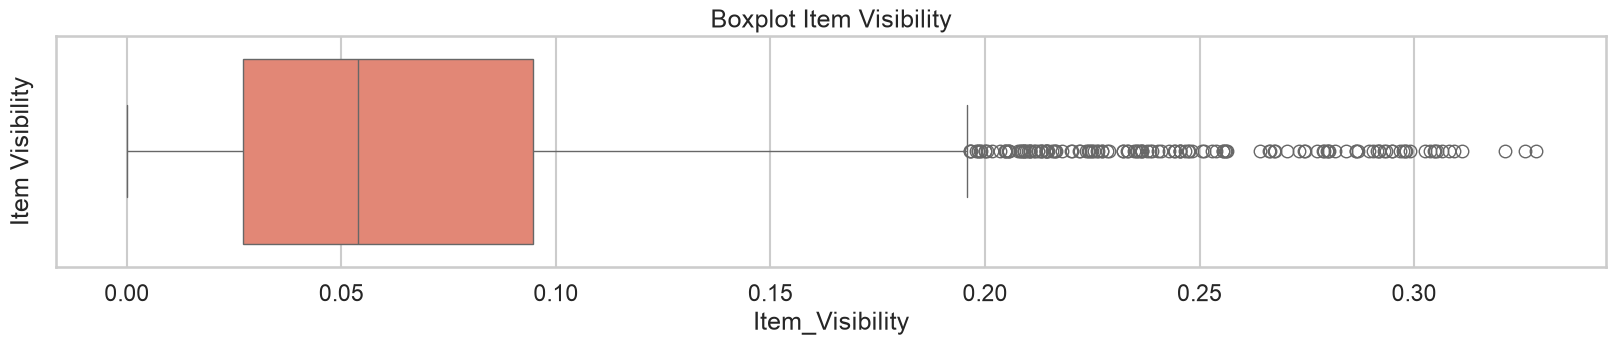

In [32]:
plt.figure(figsize=(20, 3))

sns.boxplot(x=bigmart_copy["Item_Visibility"])

plt.title("Boxplot Item Visibility")
plt.ylabel("Item Visibility")

plt.show()

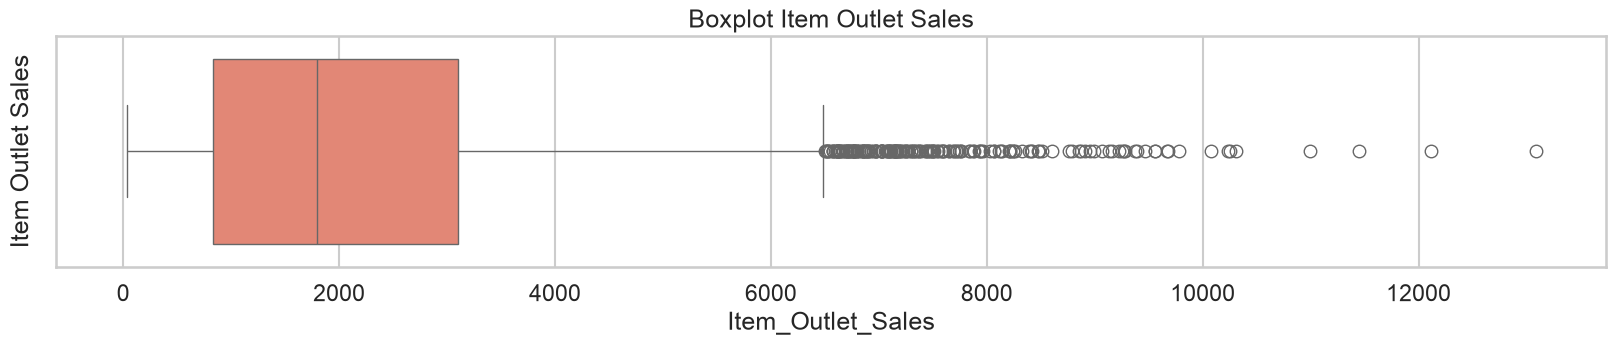

In [33]:
plt.figure(figsize=(20, 3))

sns.boxplot(x=bigmart_copy["Item_Outlet_Sales"])

plt.title("Boxplot Item Outlet Sales")
plt.ylabel("Item Outlet Sales")

plt.show()

In [34]:
Q1_visible = bigmart_copy["Item_Visibility"].quantile(0.25)
Q3_visible = bigmart_copy["Item_Visibility"].quantile(0.75)
IQR_visible = Q3_visible - Q1_visible
lower_visible = Q1_visible - 1.5 * IQR_visible
upper_visible = Q3_visible + 1.5 * IQR_visible

bigmart_copy["Visible_Cap"] = bigmart_copy["Item_Visibility"].clip(lower_visible, upper_visible) 
Q1_visible_cap = bigmart_copy["Visible_Cap"].quantile(0.25)
Q3_visible_cap = bigmart_copy["Visible_Cap"].quantile(0.75)
IQR_visible_cap = Q3_visible_cap - Q1_visible_cap
lower_visible_cap = Q1_visible_cap - 1.5 * IQR_visible_cap
upper_visible_cap = Q3_visible_cap + 1.5 * IQR_visible_cap
outlier_visible_cap = (bigmart_copy["Visible_Cap"] < lower_visible_cap) | (bigmart_copy["Visible_Cap"] > upper_visible_cap)
jumlah_outlier_visible_cap = outlier_visible_cap.sum() 
persentase_outlier_visible_cap = jumlah_outlier_visible_cap/len(bigmart_copy) * 100 
print(f"Jumlah Outlier pada Kolom Visible_Cap : {jumlah_outlier_visible_cap}")
print(f"Persentase Outlier pada Kolom Visible_Cap : {persentase_outlier_visible_cap}")

Jumlah Outlier pada Kolom Visible_Cap : 0
Persentase Outlier pada Kolom Visible_Cap : 0.0


In [35]:
Q1_sales = bigmart_copy["Item_Outlet_Sales"].quantile(0.25)
Q3_sales = bigmart_copy["Item_Outlet_Sales"].quantile(0.75)
IQR_sales = Q3_sales - Q1_sales
lower_sales = Q1_sales - 1.5 * IQR_sales
upper_sales = Q3_sales + 1.5 * IQR_sales

bigmart_copy["Sales_Cap"] = bigmart_copy["Item_Outlet_Sales"].clip(lower_sales, upper_sales) 
Q1_sales_cap = bigmart_copy["Sales_Cap"].quantile(0.25)
Q3_sales_cap = bigmart_copy["Sales_Cap"].quantile(0.75)
IQR_sales_cap = Q3_sales_cap - Q1_sales_cap
lower_sales_cap = Q1_sales_cap - 1.5 * IQR_sales_cap
upper_sales_cap = Q3_sales_cap + 1.5 * IQR_sales_cap
outlier_sales_cap = (bigmart_copy["Sales_Cap"] < lower_sales_cap) | (bigmart_copy["Sales_Cap"] > upper_sales_cap)
jumlah_outlier_sales_cap = outlier_sales_cap.sum()
persentase_outlier_sales_cap = jumlah_outlier_sales_cap/len(bigmart_copy) * 100 
print(f"Jumlah Outlier pada Kolom Sales_Cap : {jumlah_outlier_sales_cap}")
print(f"Persentase Outlier pada Kolom Sales_Cap : {persentase_outlier_sales_cap}")

Jumlah Outlier pada Kolom Sales_Cap : 0
Persentase Outlier pada Kolom Sales_Cap : 0.0


Outlier pada kolom Item_Visibility dan Item_Outlet_Sales berhasil ditangani dengan metode Capping

Alasan penanganan menggunakan metode Capping:

Item_Visibility = 

•	Menghapus data dapat mengurangi jumlah observasi

•	Capping mempertahankan seluruh baris data

Item_Outlet_Sales =

•	Nilai sales yang sangat tinggi belum tentu merupakan kesalahan

•	Produk tertentu memang bisa memiliki penjualan jauh lebih tinggi dibandingkan produk lainnya

##### Visualisasi boxplot outlier setelah ditangani dengan metode capping

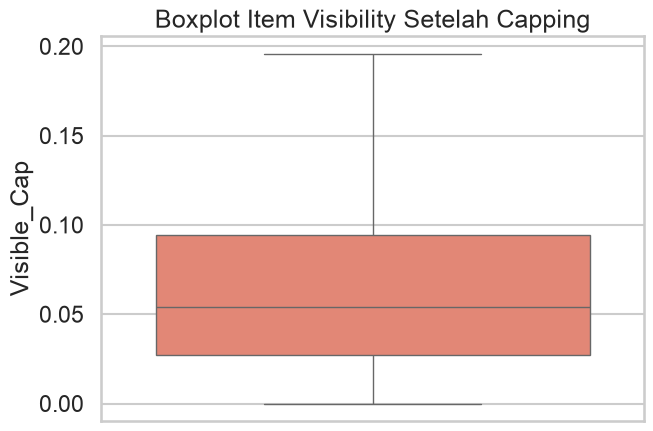

In [36]:
plt.figure(figsize=(7, 5))

sns.boxplot(y=bigmart_copy["Visible_Cap"])

plt.title("Boxplot Item Visibility Setelah Capping")
plt.ylabel("Visible_Cap")

plt.show()

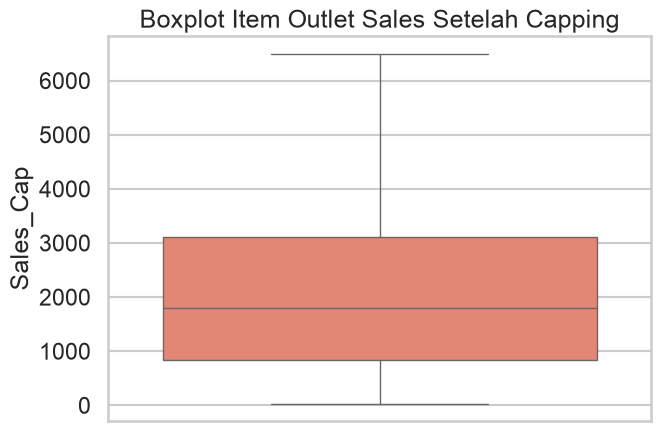

In [37]:
plt.figure(figsize=(7, 5))

sns.boxplot(y=bigmart_copy["Sales_Cap"])

plt.title("Boxplot Item Outlet Sales Setelah Capping")
plt.ylabel("Sales_Cap")

plt.show()

### Pengecekan ulang untuk tipe data

In [38]:
bigmart_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Item_Identifier            8523 non-null   str           
 1   Item_Weight                8523 non-null   float64       
 2   Item_Fat_Content           8523 non-null   str           
 3   Item_Visibility            8523 non-null   float64       
 4   Item_Type                  8523 non-null   str           
 5   Item_MRP                   8523 non-null   float64       
 6   Outlet_Identifier          8523 non-null   str           
 7   Outlet_Establishment_Year  8523 non-null   datetime64[us]
 8   Outlet_Size                8523 non-null   str           
 9   Outlet_Location_Type       8523 non-null   str           
 10  Outlet_Type                8523 non-null   str           
 11  Item_Outlet_Sales          8523 non-null   float64       
 12  Visible_Cap      

Semua tipe data sudah sesuai, format tanggal yang sebelum nya integer sudah berubah menjadi datetime

## Perbandingan dataset sebelum dan sesudah cleaning

In [39]:
bigmart.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [40]:
bigmart_copy.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Visible_Cap,Sales_Cap
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,3735.1380,0.016047,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,443.4228,0.019278,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,2097.2700,0.016760,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998-01-01,Medium,Tier 3,Grocery Store,732.3800,0.000000,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,994.7052,0.000000,994.7052


Dataset sebelum dilakukannya cleaning terdapat inkonsistensi pada kolom Item_Fat_Content setelah dilakukan cleaning maka kolom Item_Fat_Content sudah memiliki konsistensi yang sama untuk penulisannya.

Pada Item_Weight dan Outlet_Size terdapat missing value maka dilakukan penanganan dengan imputasi dengan menggunakan median dan mode

Terdapat outlier pada kolom Item_Visibility dan Item_Outlet_Sales makan dilakukan penanganan menggunakan metode capping sehingga outlier bisa ditangani dan menjadi 0%

### Feature Engineering 

In [41]:
bigmart_copy["Sales_per_MRP"] = bigmart_copy["Item_Outlet_Sales"] / bigmart_copy["Item_MRP"].round(2)
bigmart_copy

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Visible_Cap,Sales_Cap,Sales_per_MRP
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,3735.1380,0.016047,3735.1380,14.951915
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,443.4228,0.019278,443.4228,9.186302
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999-01-01,Medium,Tier 1,Supermarket Type1,2097.2700,0.016760,2097.2700,14.809137
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998-01-01,Medium,Tier 3,Grocery Store,732.3800,0.000000,732.3800,4.021856
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,994.7052,0.000000,994.7052,18.468348
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987-01-01,High,Tier 3,Supermarket Type1,2778.3834,0.056783,2778.3834,12.951629
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002-01-01,Medium,Tier 2,Supermarket Type1,549.2850,0.046982,549.2850,5.078449
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004-01-01,Small,Tier 2,Supermarket Type1,1193.1136,0.035186,1193.1136,14.016842
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009-01-01,Medium,Tier 3,Supermarket Type2,1845.5976,0.145221,1845.5976,17.895836


### Encoder dataset agar data siap untuk diuji statistik

In [42]:
le = LabelEncoder()

In [43]:
bigmart_copy["Item_Identifier_Code"] = le.fit_transform(bigmart_copy["Item_Identifier"])
bigmart_copy["Item_Fat_Code"] = le.fit_transform(bigmart_copy["Item_Fat_Content"])
bigmart_copy["Item_Type_Code"] = le.fit_transform(bigmart_copy["Item_Type"])
bigmart_copy["Outlet_Identifier_Code"] = le.fit_transform(bigmart_copy["Outlet_Identifier"])
bigmart_copy["Outlet_Size_Code"] = le.fit_transform(bigmart_copy["Outlet_Size"])
bigmart_copy["Outlet_Location_Code"] = le.fit_transform(bigmart_copy["Outlet_Location_Type"])
bigmart_copy["Outlet_Type_Code"] = le.fit_transform(bigmart_copy["Outlet_Type"])

In [44]:
bigmart_statistik = bigmart_copy[["Item_Identifier_Code","Item_Weight","Item_Fat_Code","Item_Visibility","Item_Type_Code","Item_MRP","Outlet_Identifier_Code","Outlet_Establishment_Year","Outlet_Size_Code","Outlet_Location_Code","Outlet_Type_Code","Item_Outlet_Sales","Visible_Cap","Sales_Cap"]]

In [45]:
bigmart_statistik

,Item_Identifier_Code,Item_Weight,Item_Fat_Code,Item_Visibility,Item_Type_Code,Item_MRP,Outlet_Identifier_Code,Outlet_Establishment_Year,Outlet_Size_Code,Outlet_Location_Code,Outlet_Type_Code,Item_Outlet_Sales,Visible_Cap,Sales_Cap
0,156,9.300,0,0.016047,4,249.8092,9,1999-01-01,1,0,1,3735.1380,0.016047,3735.1380
1,8,5.920,1,0.019278,14,48.2692,3,2009-01-01,1,2,2,443.4228,0.019278,443.4228
2,662,17.500,0,0.016760,10,141.6180,9,1999-01-01,1,0,1,2097.2700,0.016760,2097.2700
3,1121,19.200,1,0.000000,6,182.0950,0,1998-01-01,1,2,0,732.3800,0.000000,732.3800
4,1297,8.930,0,0.000000,9,53.8614,1,1987-01-01,0,2,1,994.7052,0.000000,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,370,6.865,0,0.056783,13,214.5218,1,1987-01-01,0,2,1,2778.3834,0.056783,2778.3834
8519,897,8.380,1,0.046982,0,108.1570,7,2002-01-01,1,1,1,549.2850,0.046982,549.2850
8520,1357,10.600,0,0.035186,8,85.1224,6,2004-01-01,2,1,1,1193.1136,0.035186,1193.1136
8521,681,7.210,1,0.145221,13,103.1332,3,2009-01-01,1,2,2,1845.5976,0.145221,1845.5976


### Distribusi setelah cleaning dan encoding

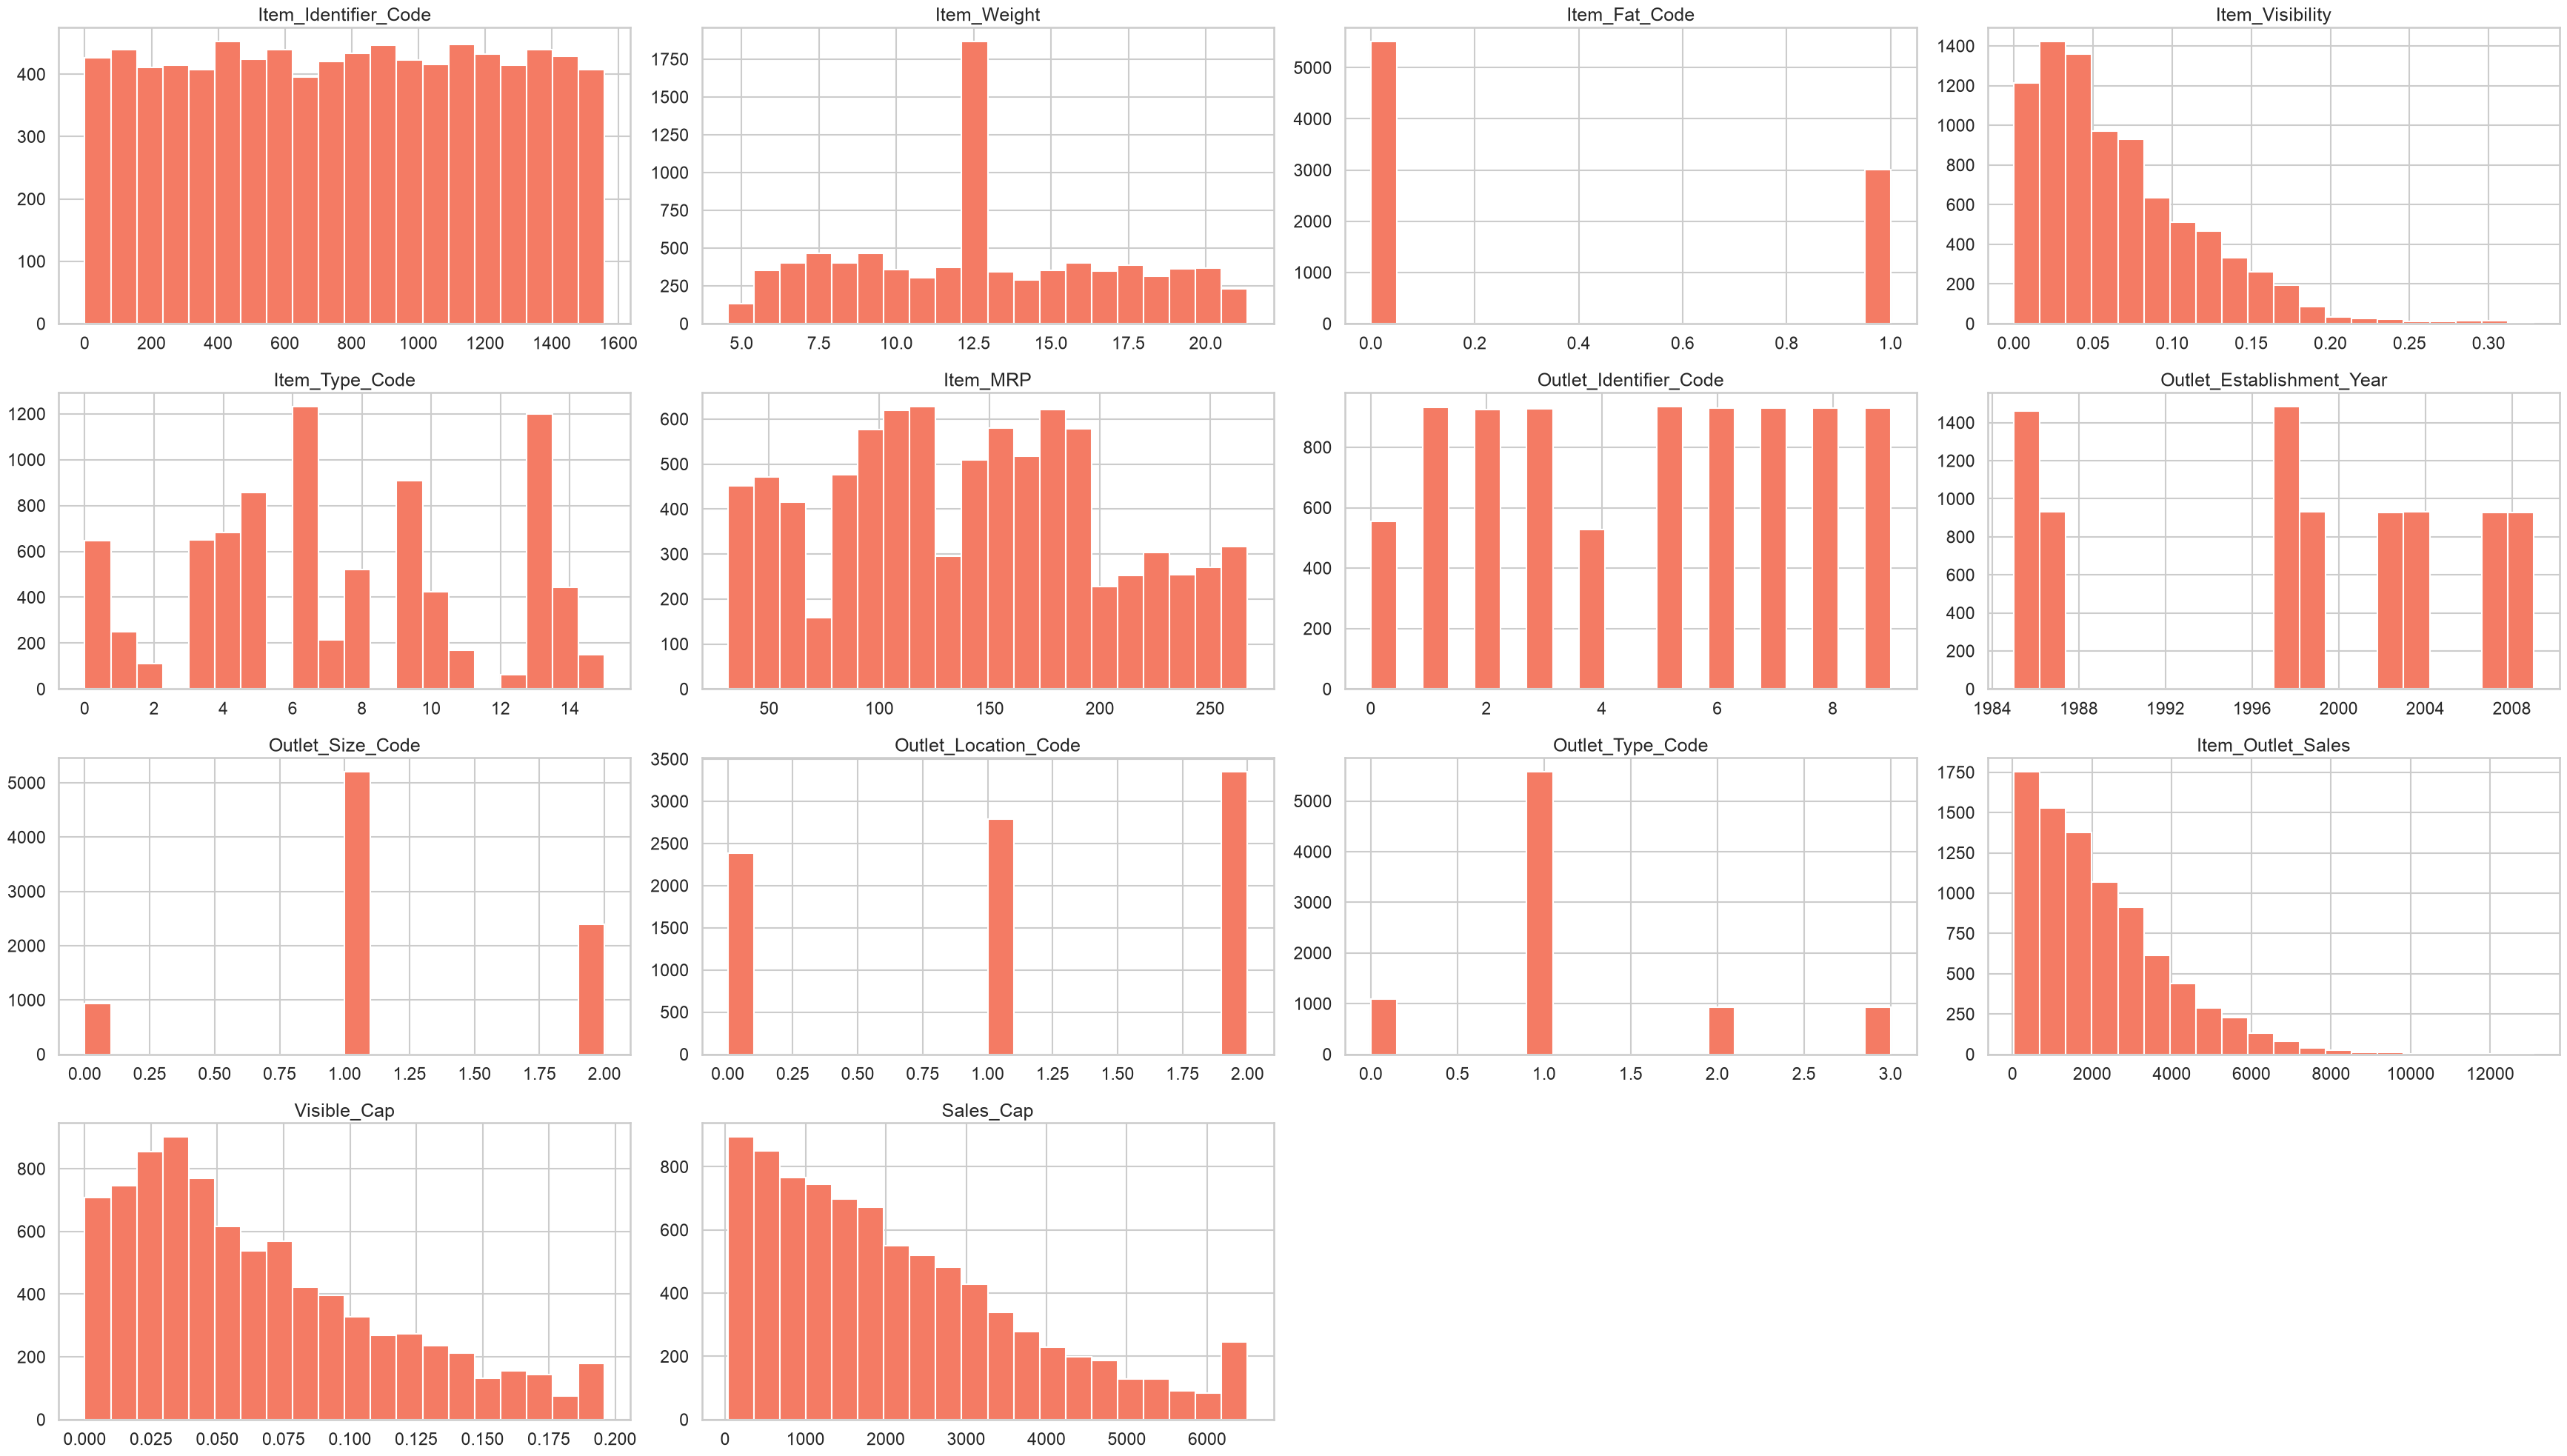

In [46]:
bigmart_statistik.hist(
    bins=20,
    figsize=(35, 20)
)

plt.tight_layout()
plt.show()

Tidak terdapat distribusi yang normal setelah dilakukannya cleaning dan juga handling outlier

### Buat dataset untuk analisa

In [47]:
bigmart_analisa = bigmart_copy[["Item_Fat_Content","Item_Type","Item_MRP","Outlet_Size","Outlet_Location_Type","Outlet_Type","Item_Outlet_Sales"]]

In [48]:
bigmart_analisa

,Item_Fat_Content,Item_Type,Item_MRP,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,Low Fat,Dairy,249.8092,Medium,Tier 1,Supermarket Type1,3735.1380
1,Regular,Soft Drinks,48.2692,Medium,Tier 3,Supermarket Type2,443.4228
2,Low Fat,Meat,141.6180,Medium,Tier 1,Supermarket Type1,2097.2700
3,Regular,Fruits and Vegetables,182.0950,Medium,Tier 3,Grocery Store,732.3800
4,Low Fat,Household,53.8614,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...
8518,Low Fat,Snack Foods,214.5218,High,Tier 3,Supermarket Type1,2778.3834
8519,Regular,Baking Goods,108.1570,Medium,Tier 2,Supermarket Type1,549.2850
8520,Low Fat,Health and Hygiene,85.1224,Small,Tier 2,Supermarket Type1,1193.1136
8521,Regular,Snack Foods,103.1332,Medium,Tier 3,Supermarket Type2,1845.5976


# EDA

## DATA MANIPULATION

## Penerapan Grouping, Fungsi Agregasi, bivariate, multivariate,dan juga cross tabulation

In [49]:
bigmart_copy.groupby("Item_Type").agg(
    Rata_Rata_MRP=("Item_MRP", "mean"),
    Rata_Rata_Sales=("Item_Outlet_Sales", "mean")
).sort_values(
    by="Rata_Rata_MRP",
    ascending=False
).head(5)

,Rata_Rata_MRP,Rata_Rata_Sales
Item_Type,,
Household,149.424753,2258.784300
Dairy,148.499208,2232.542597
Starchy Foods,147.838023,2374.332773
Snack Foods,146.194934,2277.321739
Fruits and Vegetables,144.581235,2289.009592


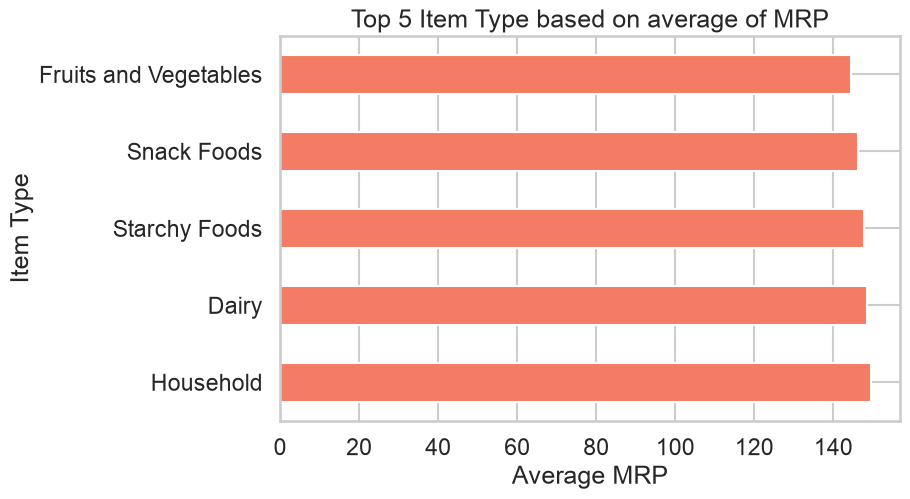

In [50]:
hasil = bigmart_copy.groupby("Item_Type")["Item_MRP"].mean().sort_values(ascending=False).head(5)

hasil.plot(kind="barh", figsize=(8,5))
plt.xlabel("Average MRP")
plt.ylabel("Item Type")
plt.title("Top 5 Item Type based on average of MRP")
plt.show()

Item_Type Household memiliki rata-rata MRP tertinggi, meskipun memiliki harga tertinggi namun hasil penjualan ternyata masih kurang dibanding dengan Item_Type yang lain, maka dari itu strategi harga seperti diskon dan bundling dapat digunakan untuk meningkatkan daya tarik produk dan mendorong penjualan.

In [51]:
bigmart_copy.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].agg(["mean"]).rename(
    columns={"mean": "Rata_Rata_Sales"}
).sort_values(
    by="Rata_Rata_Sales",
    ascending=False
).round(2)

,Rata_Rata_Sales
Outlet_Location_Type,
Tier 2,2323.99
Tier 3,2279.63
Tier 1,1876.91


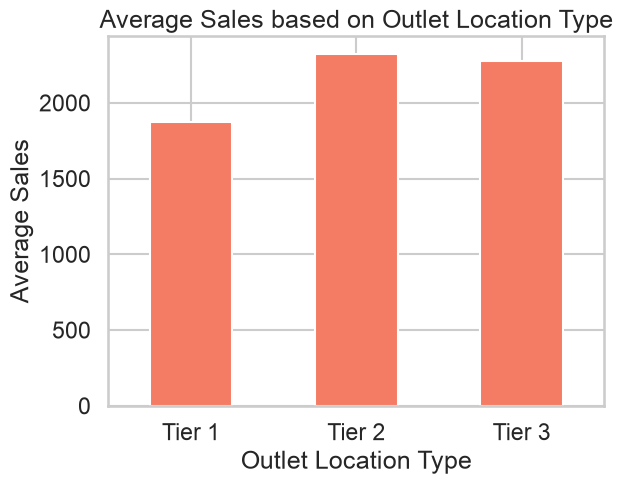

In [52]:
hasil = bigmart_copy.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].mean()

hasil.plot(kind="bar")

plt.xlabel("Outlet Location Type")
plt.ylabel("Average Sales")
plt.title("Average Sales based on Outlet Location Type")
plt.xticks(rotation=0)
plt.show()

Tier 2 memiliki rata-rata Item_Outlet_Sales tertinggi sebesar 2323.99, diikuti oleh Tier 3 sebesar 2279.63, sedangkan Tier 1 memiliki rata-rata sales terendah sebesar 1876.91. Hal ini menunjukkan bahwa outlet pada lokasi Tier 2 memiliki performa penjualan rata-rata paling tinggi dibandingkan lokasi lainnya.
Sehingga bisa memprioritaskan kepada Location type Tier 2 untuk menaikan penjualan 

In [53]:
bigmart_copy.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].agg(["sum"]).rename(
    columns={"sum": "Total_Location_Sales"}
).sort_values(
    by="Total_Location_Sales",
    ascending=False
).round(2)

,Total_Location_Sales
Outlet_Location_Type,
Tier 3,7636752.63
Tier 2,6472313.71
Tier 1,4482059.07


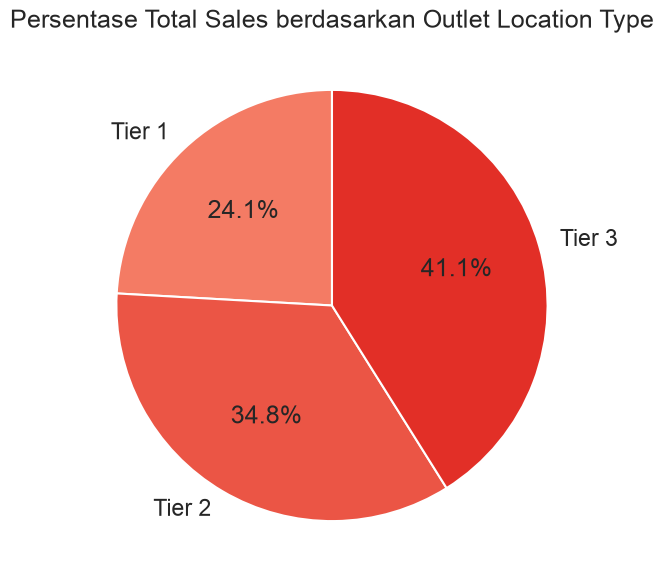

In [54]:
hasil = bigmart_copy.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    hasil,
    labels=hasil.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Persentase Total Sales berdasarkan Outlet Location Type")
plt.show()

Dari perbandingan 2 chart tersebut kita bisa mengambil 2 insight:

1.Jika kita ingin melihat performa rata-rata, maka Tier 2 lah yang memberikan performa tinggi 

2.Jika kita ingin melihat tier mana yang memberikan revenue tinggi maka Tier 3 lah yang memberikan revenue yang paling tinggi 

In [55]:
bigmart_copy.groupby(
    ["Item_Fat_Content", "Item_Type"]
)["Item_Outlet_Sales"].agg(["mean"]).rename(
    columns={"mean": "Rata_Rata_Sales"}
).sort_values(
    by="Rata_Rata_Sales",
    ascending=False
).head(5)

Rata_Rata_Sales
Item_Fat_Content Item_Type                             
Regular          Seafood                    2899.263089
Low Fat          Starchy Foods              2558.425815
                 Breakfast                  2425.411966
                 Snack Foods                2411.978843
Regular          Fruits and Vegetables      2400.571761

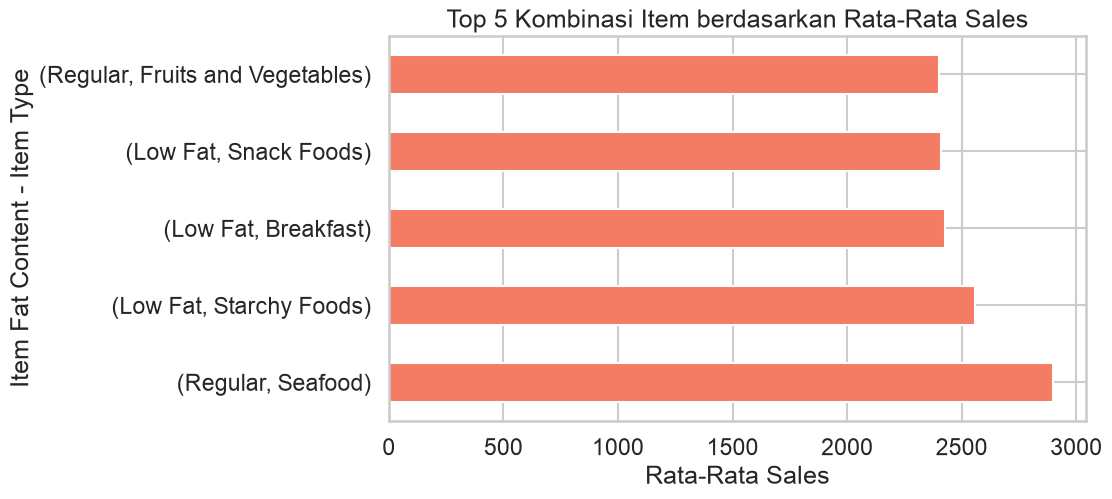

In [56]:
hasil = bigmart_copy.groupby(
    ["Item_Fat_Content", "Item_Type"]
)["Item_Outlet_Sales"].mean().sort_values(ascending=False).head(5)

hasil.plot(kind="barh", figsize=(9, 5))

plt.xlabel("Rata-Rata Sales")
plt.ylabel("Item Fat Content - Item Type")
plt.title("Top 5 Kombinasi Item berdasarkan Rata-Rata Sales")
plt.show()

Seafood memiliki performa penjualan tertinggi sebesar 2899.26, sedangkan fruits and vegetables memiliki rata-rata sales terendah dari 5 kombinasi yang dianalisis, yaitu 2400.57 

Kategori Regular maupun Low Fat tidak konsisten menghasilkan sales yang lebih tinggi, sehingga Item_Type menjadi faktor yang lebih mempengaruhi dalam perbedaan penjualan.

Fokus terhadap Item_Type khusus nya seafood jika ingin memperoleh hasil sales yang maksimal

In [57]:
crosstab_sales = pd.crosstab(
    bigmart_copy["Item_Fat_Content"],
    bigmart_copy["Item_Type"],
    values=bigmart_copy["Item_Outlet_Sales"],
    aggfunc="mean"
)

crosstab_sales

Item_Type,Baking Goods,Breads,Breakfast,Canned,Dairy,Frozen Foods,Fruits and Vegetables,Hard Drinks,Health and Hygiene,Household,Meat,Others,Seafood,Snack Foods,Soft Drinks,Starchy Foods
Item_Fat_Content,,,,,,,,,,,,,,,,
Low Fat,1764.509636,2183.434031,2425.411966,2208.714377,2145.174151,2117.535472,2182.405740,2139.221622,2010.000265,2258.7843,2035.616920,1926.139702,1907.786919,2411.978843,2035.452072,2558.425815
Regular,2147.340665,2230.238058,1925.464652,2243.441202,2370.875970,2149.861640,2400.571761,NaN,NaN,NaN,2241.218571,NaN,2899.263089,2093.891196,1854.065451,2145.611115


Perbedaan Item_Fat_Content tidak menunjukkan pola yang konsisten terhadap penjualan. Produk regular memiliki penjualan lebih tinggi pada beberapa kategori seperti Seafood dan Fruits and Vegetables, sementara low fat lebih tinggi pada kategori seperti Breakfast dan Starchy Foods. Oleh karena itu, strategi penjualan sebaiknya lebih berfokus pada Item_Type daripada hanya mengandalkan kategori Item_Fat_Content.

Penjualan untuk tipe kandungan Low Fat di dominasi oleh Item_Type Starchy Foods

Sedangkan untuk tipe kandungan Regular di dominasi oleh Item_Type Seafood

In [58]:
crosstab_outlet = pd.crosstab(
    bigmart_copy["Outlet_Location_Type"],
    bigmart_copy["Outlet_Type"],
    values=bigmart_copy["Item_Outlet_Sales"],
    aggfunc="mean"
)

crosstab_outlet

Outlet_Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Outlet_Location_Type,,,,
Tier 1,340.329723,2313.099451,NaN,NaN
Tier 2,NaN,2323.990559,NaN,NaN
Tier 3,339.351662,2298.995256,1995.498739,3694.038558


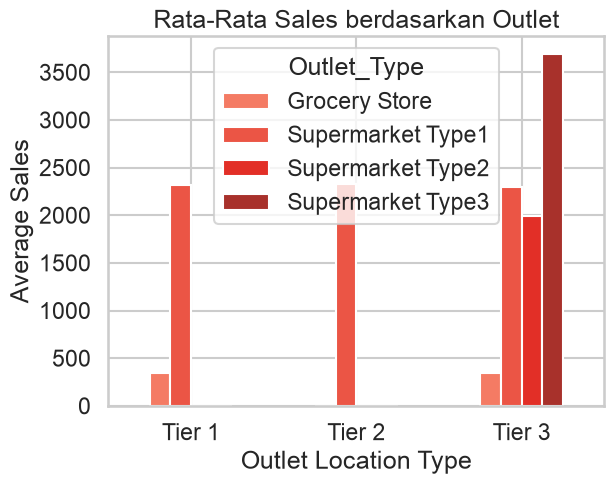

In [59]:
crosstab_outlet.plot(kind="bar")

plt.title("Rata-Rata Sales berdasarkan Outlet")
plt.xlabel("Outlet Location Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

Supermarket Tipe 1 cenderung menunjukkan penjualan yang konsisten di berbagai tipe lokasi, sementara Supermarket Tipe 3 (Tier 3) menghasilkan penjualan terbaik. Oleh karena itu, strategi pengembangan jenis outlet sebaiknya mempertimbangkan kombinasi antara jenis outlet dan karakteristik lokasi.

### Heatmap jika semua kolum dimasukan untuk melihat korelasinya

In [60]:
heatmaps = bigmart_copy[["Item_Identifier_Code","Item_Weight","Item_Fat_Code","Visible_Cap","Item_Type_Code","Item_MRP","Outlet_Identifier_Code","Outlet_Establishment_Year","Outlet_Size_Code","Outlet_Location_Code","Outlet_Type_Code","Sales_Cap"]]

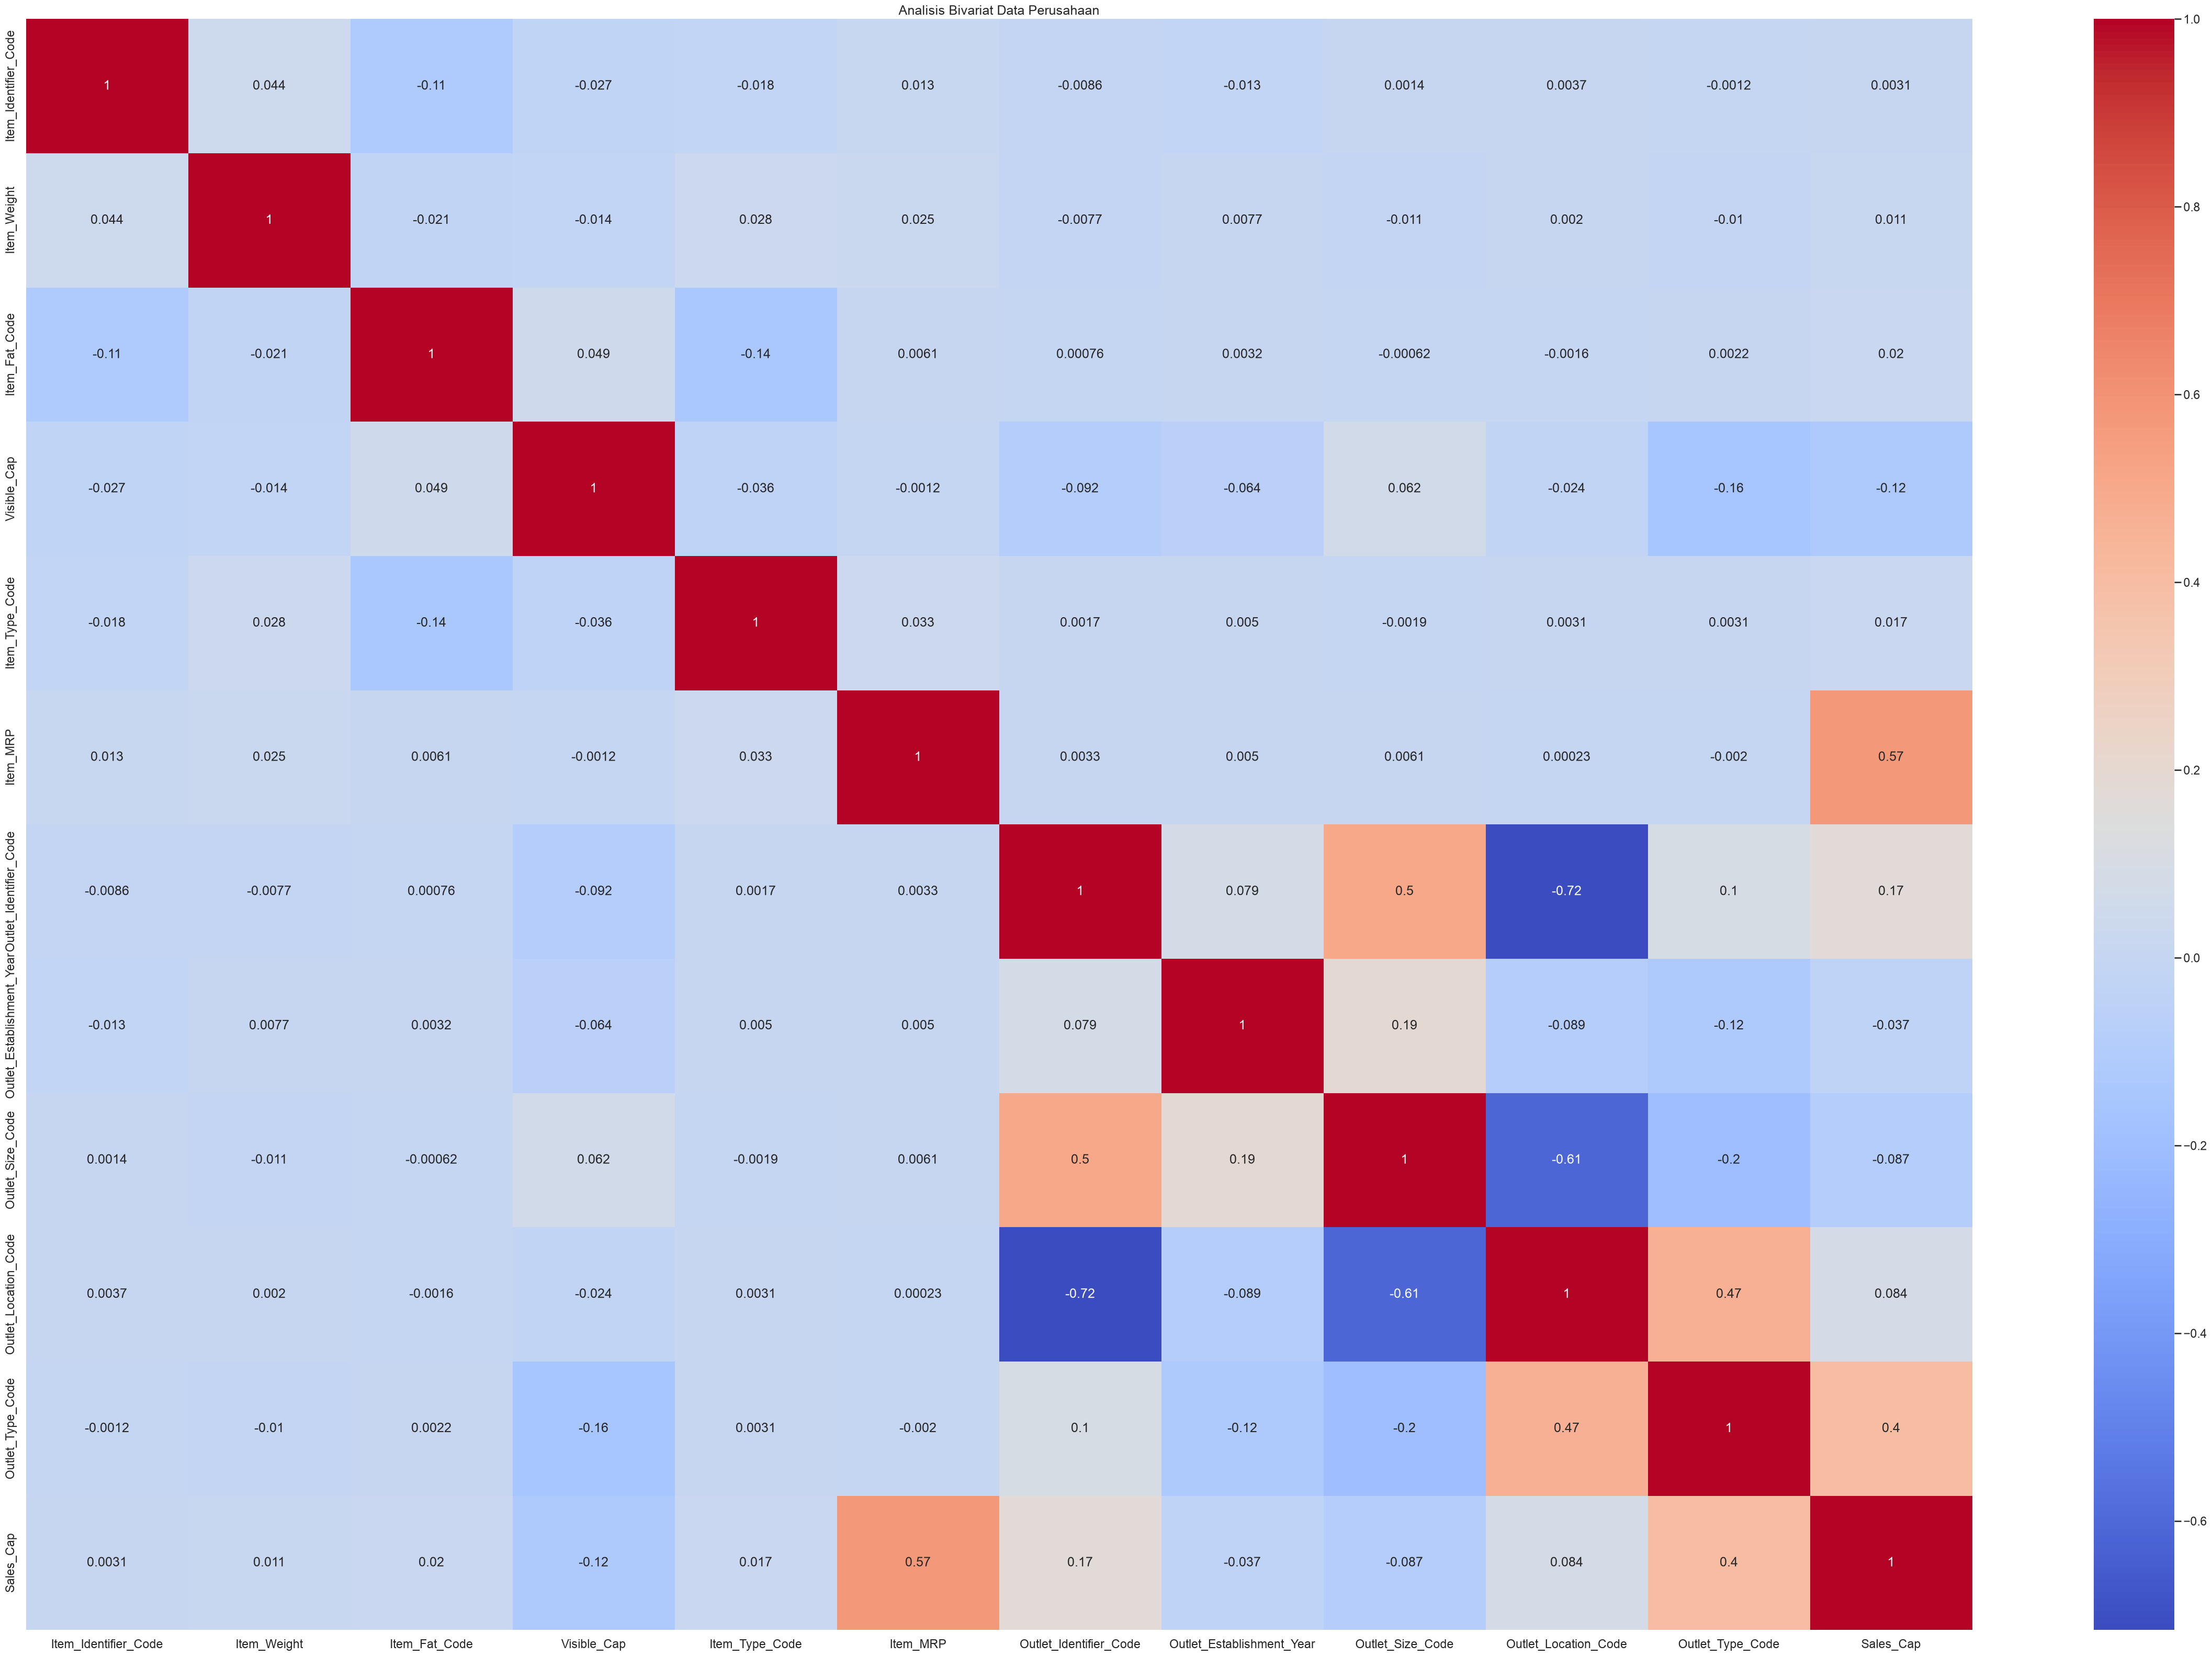

In [61]:
bigmart_corr = heatmaps.corr()
plt.figure(figsize=(60, 40))
sns.heatmap(
    bigmart_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.xticks(rotation=0)
plt.show()

### Heatmap berdasarkan kolom numerik

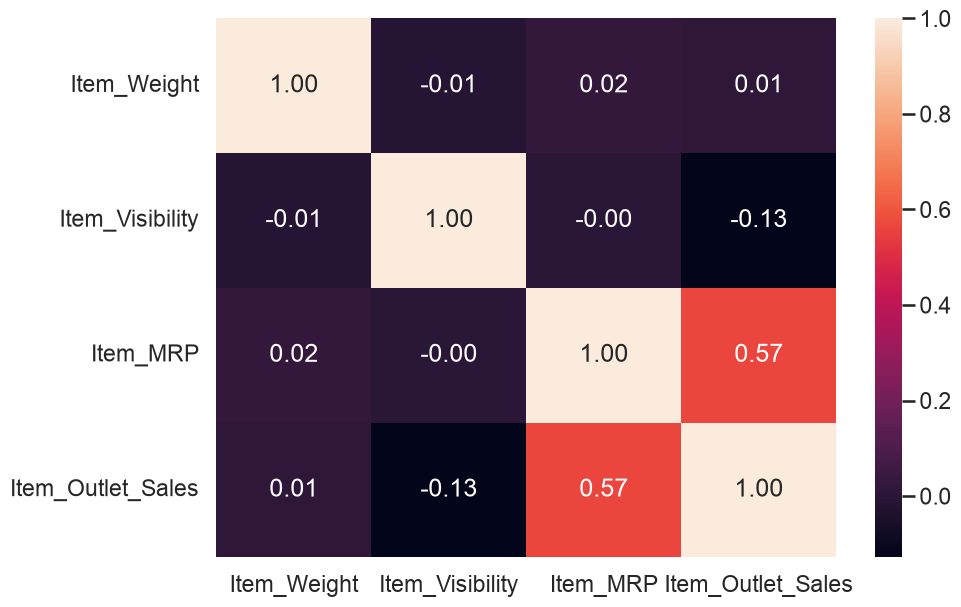

In [62]:
bigmart_copy[
    ["Item_Weight",
     "Item_Visibility",
     "Item_MRP",
     "Item_Outlet_Sales"]
].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    bigmart_copy[
        ["Item_Weight",
         "Item_Visibility",
         "Item_MRP",
         "Item_Outlet_Sales"]
    ].corr(),
    annot=True,
    fmt=".2f"
)
plt.xticks(rotation=0)
plt.show()

Berdasarkan heatmap tersebut terlihat hubungan yang kuat antara Item_MRP dan juga Item_Outlet_Sales.

Maka harga barang sangat mempengaruhi untuk hasil penjualan

#### Randomisasi

In [64]:
sample_data = bigmart_copy.sample(n=500,random_state=42)
sample_data

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,...,Visible_Cap,Sales_Cap,Sales_per_MRP,Item_Identifier_Code,Item_Fat_Code,Item_Type_Code,Outlet_Identifier_Code,Outlet_Size_Code,Outlet_Location_Code,Outlet_Type_Code
7503,FDI28,14.300,Low Fat,0.026300,Frozen Foods,79.4302,OUT013,1987-01-01,High,Tier 3,...,0.026300,1743.0644,21.944661,487,0,5,1,0,2,1
2957,NCM17,7.930,Low Fat,0.071136,Health and Hygiene,42.7086,OUT046,1997-01-01,Small,Tier 1,...,0.071136,356.8688,8.355626,1392,0,8,8,2,0,1
7031,FDC14,14.500,Regular,0.041313,Canned,42.0454,OUT049,1999-01-01,Medium,Tier 1,...,0.041313,377.5086,8.977612,244,1,3,9,1,0,1
1084,DRC36,12.600,Regular,0.044767,Soft Drinks,173.7054,OUT027,1985-01-01,Medium,Tier 3,...,0.044767,5778.4782,33.265087,14,1,14,5,1,2,3
856,FDS27,10.195,Regular,0.012456,Meat,197.5110,OUT035,2004-01-01,Small,Tier 2,...,0.012456,2356.9320,11.933229,890,1,10,6,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1010,FDB26,14.000,Regular,0.031267,Canned,51.4640,OUT046,1997-01-01,Small,Tier 1,...,0.031267,692.4320,13.455733,208,1,3,8,2,0,1
3065,FDE10,6.670,Regular,0.090131,Snack Foods,131.4626,OUT045,2002-01-01,Medium,Tier 2,...,0.090131,1705.1138,12.970590,323,1,13,7,1,1,1
8243,FDE34,9.195,Low Fat,0.107871,Snack Foods,181.2634,OUT035,2004-01-01,Small,Tier 2,...,0.107871,2362.9242,13.036104,338,0,13,6,2,1,1
5360,FDS44,12.650,Regular,0.156680,Fruits and Vegetables,238.8538,OUT018,2009-01-01,Medium,Tier 3,...,0.156680,4566.7222,19.119624,902,1,6,3,1,2,2


Mengambil 500 baris data secara acak untuk mengecek isi semua data yang sudah melalui proses cleaning dan juga encoding